# Workshop 3

In [1]:
import kagglehub

path = kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python")
print(path)

Using Colab cache for faster access to the 'customer-segmentation-tutorial-in-python' dataset.
/kaggle/input/customer-segmentation-tutorial-in-python


In [2]:
import pandas as pd

df = pd.read_csv("/kaggle/input/customer-segmentation-tutorial-in-python/Mall_Customers.csv")

print(df.head())
print(df.shape)
df.isnull().sum()

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
(200, 5)


,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


- ¿Hay valores nulos?

R/ No hay valores nulos.
- ¿Qué tipo de dato tiene cada columna? ¿Cuáles son numéricas y cuál es categórica?

|Dato|Tipo|Num/Cat|
|-|-|-|
|CustomerID|Entero|Categórica|
|Gender|Texto|Categórica|
|Age|Entero|Numérica|
|Annual Income|Entero|Numérica|
|Spending Score|Entero|Numérica|


In [4]:
df.drop(['CustomerID'], axis=1, inplace=True)

In [5]:
df.describe()

,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


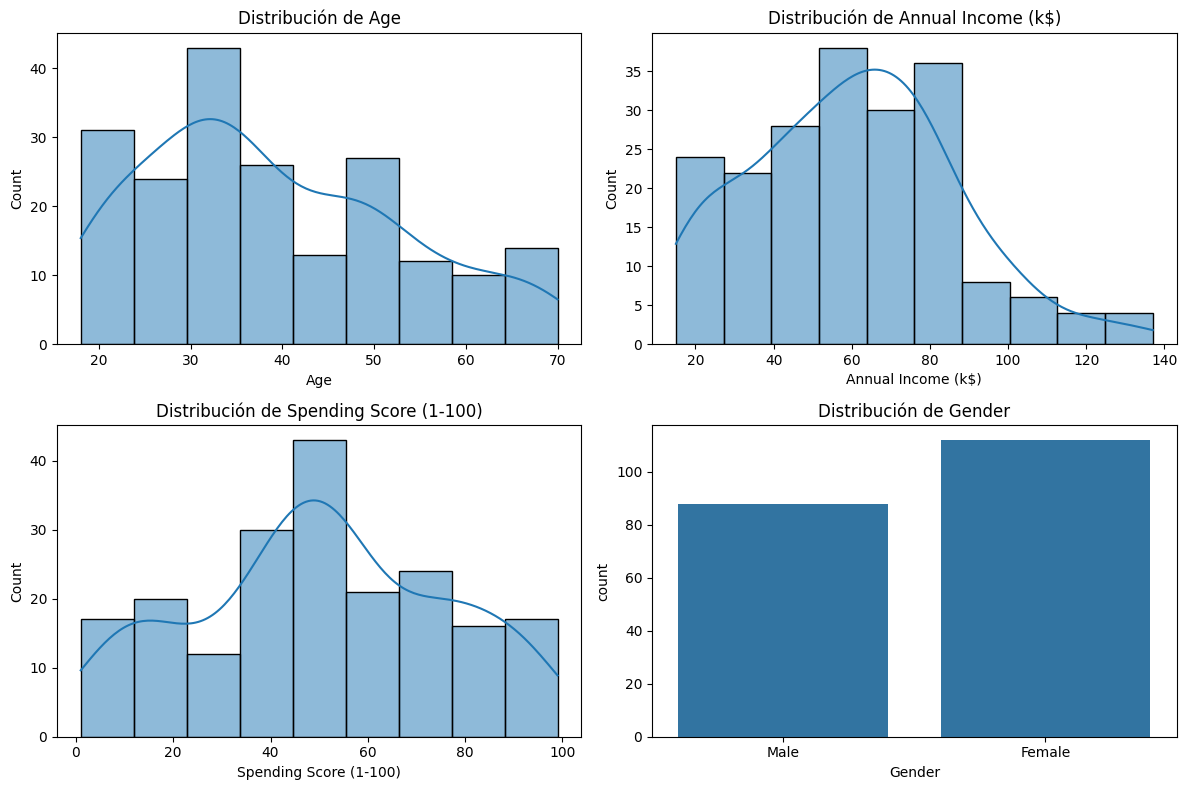

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df['Age'], kde=True, ax=axes[0, 0])
axes[0, 0].set_title('Distribución de Age')

sns.histplot(df['Annual Income (k$)'], kde=True, ax=axes[0, 1])
axes[0, 1].set_title('Distribución de Annual Income (k$)')

sns.histplot(df['Spending Score (1-100)'], kde=True, ax=axes[1, 0])
axes[1, 0].set_title('Distribución de Spending Score (1-100)')

sns.countplot(x='Gender', data=df, ax=axes[1, 1])
axes[1, 1].set_title('Distribución de Gender')

plt.tight_layout()
plt.show()

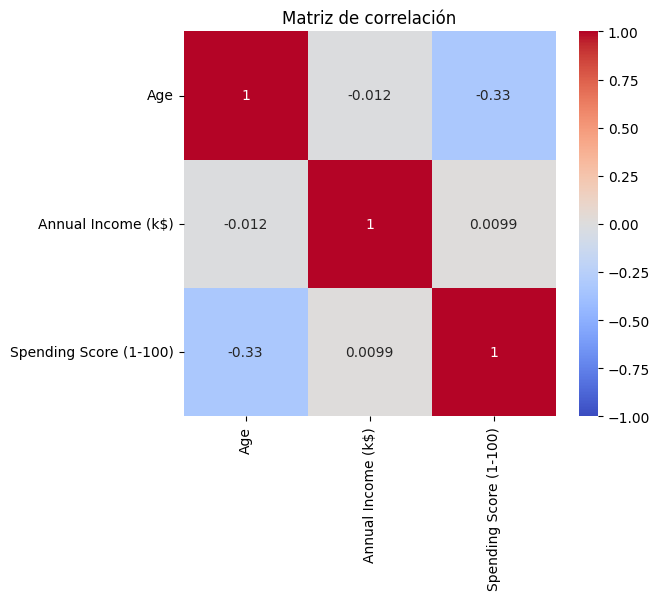

In [7]:
corr = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de correlación')
plt.show()

In [8]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(drop='if_binary', sparse_output=False)
df['Genre_encoded'] = encoder.fit_transform(df[['Gender']]).ravel()

print(encoder.categories_)
df.head()

[array(['Female', 'Male'], dtype=object)]


,Gender,Age,Annual Income (k$),Spending Score (1-100),Genre_encoded
0,Male,19,15,39,1.0
1,Male,21,15,81,1.0
2,Female,20,16,6,0.0
3,Female,23,16,77,0.0
4,Female,31,17,40,0.0


In [9]:
from sklearn.preprocessing import StandardScaler

features = ["Genre_encoded", "Age", "Annual Income (k$)", "Spending Score (1-100)"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

- ¿Por qué es importante estandarizar antes de aplicar K-Means, Agglomerative Clustering o DBSCAN? (Piensen específicamente en qué pasaría si NO estandarizaran — comparen las escalas de `Age` vs. `Annual Income (k$)`).

R/ Datos no estandarizados se distribuyen irregularmente dependiendo de las magnitudes de sus features numéricas y los algoritmos dependen del cálculo de distancias entre estas, esto podría causar clústers sesgados o fragmentados por la variabilidad de una variable específica, por ejemplo annual income en este caso teniendo un rango más amplio que otras y estando sesgada a la derecha. Estandarizar permite homogeneizar la variabilidad de las features para obtener clústers más precisos e interpretables.

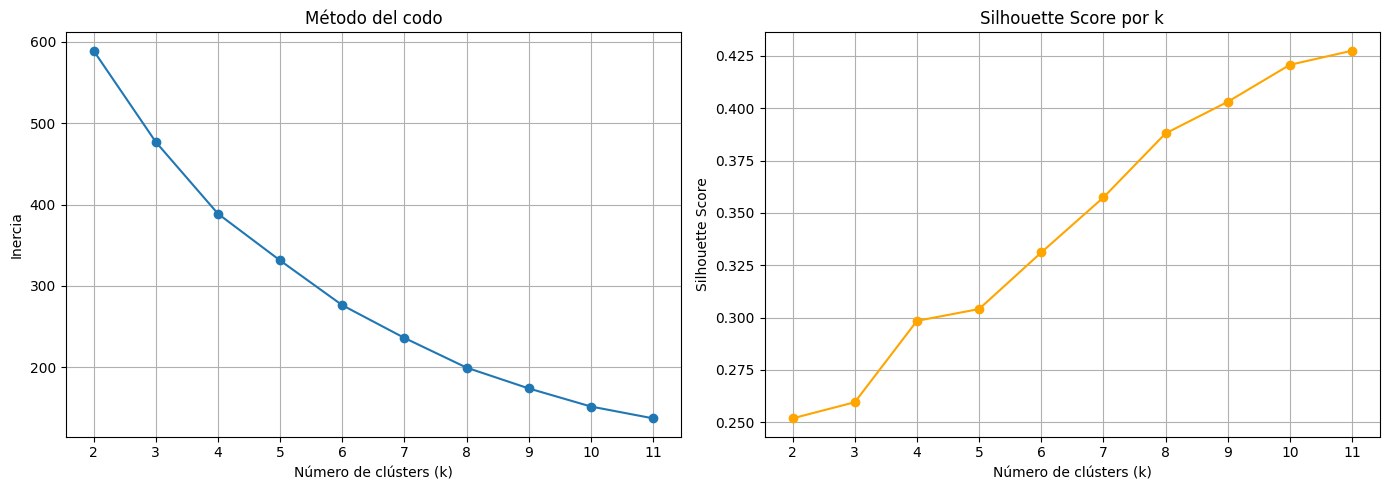

In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias = []
silhouette_scores = []
ks = range(2, 12)

for k in ks:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, model.labels_))

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(ks, inertias, marker='o')
axes[0].set_xlabel('Número de clústers (k)')
axes[0].set_ylabel('Inercia')
axes[0].set_title('Método del codo')
axes[0].set_xticks(list(ks))
axes[0].grid(True)

axes[1].plot(ks, silhouette_scores, marker='o', color='orange')
axes[1].set_xlabel('Número de clústers (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score por k')
axes[1].set_xticks(list(ks))
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [11]:
comparison_df = pd.DataFrame({
    "k": list(ks),
    "inertia": inertias,
    "silhouette": silhouette_scores
})
comparison_df

,k,inertia,silhouette
0,2,588.802677,0.251815
1,3,476.787554,0.259513
2,4,388.717861,0.298397
3,5,331.309884,0.304060
4,6,276.411760,0.331074
5,7,236.204947,0.357377
6,8,199.750461,0.387993
7,9,174.235477,0.403092
8,10,152.029834,0.420764
9,11,137.497372,0.427507


- 1. ¿El codo de la curva de inercia coincide con el `k` de mayor Silhouette Score?

R/ Aunque la curva de la inercia entre los valores de k es relativamente suave, se evidencia un último incremento significativo de el silhouette score en k=4.
- 2. ¿Qué `k` seleccionarían para K-Means? Justifiquen.

R/ Selección k=4 

,k,Silhouette
0,2,0.242
1,3,0.248
2,4,0.263
3,5,0.287
4,6,0.310
5,7,0.346
6,8,0.379
7,9,0.392
8,10,0.418
9,11,0.425


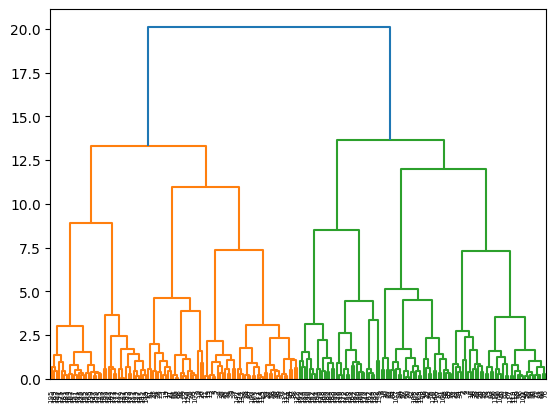

In [12]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

Z = linkage(X_scaled, method="ward")
dendrogram(Z)

silhouettes_agg = []

for k in ks:
    labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_scaled)
    silhouettes_agg.append(silhouette_score(X_scaled, labels))

tabla_agg = pd.DataFrame({"k": ks, "Silhouette": silhouettes_agg})
tabla_agg.round(3)

- ¿Cuántos grupos sugiere el dendrograma visualmente?

R/ Sugiere entre 4, 5 y 6 clústers, en alturas 12.5, 12 y 10 respectivamente.
- ¿Coincide con el mejor `k` según Silhouette Score?

R/ Sí

# FASE 3. DBSCAN

In [13]:
from sklearn.cluster import DBSCAN

for eps in [0.3, 0.5, 0.7, 0.9, 1.1]:
    for min_samples in [3, 5, 8, 10]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
        n_ruido = list(labels).count(-1)
        n_clusters = len(set(labels)) - (1 if n_ruido > 0 else 0)
        print(f"eps={eps}, min_samples={min_samples}: {n_clusters} clusters, {n_ruido} ruido")

eps=0.3, min_samples=3: 14 clusters, 144 ruido
eps=0.3, min_samples=5: 1 clusters, 194 ruido
eps=0.3, min_samples=8: 0 clusters, 200 ruido
eps=0.3, min_samples=10: 0 clusters, 200 ruido
eps=0.5, min_samples=3: 18 clusters, 49 ruido
eps=0.5, min_samples=5: 9 clusters, 105 ruido
eps=0.5, min_samples=8: 2 clusters, 169 ruido
eps=0.5, min_samples=10: 2 clusters, 178 ruido
eps=0.7, min_samples=3: 9 clusters, 14 ruido
eps=0.7, min_samples=5: 7 clusters, 37 ruido
eps=0.7, min_samples=8: 5 clusters, 76 ruido
eps=0.7, min_samples=10: 5 clusters, 106 ruido
eps=0.9, min_samples=3: 3 clusters, 8 ruido
eps=0.9, min_samples=5: 2 clusters, 13 ruido
eps=0.9, min_samples=8: 4 clusters, 25 ruido
eps=0.9, min_samples=10: 5 clusters, 46 ruido
eps=1.1, min_samples=3: 2 clusters, 0 ruido
eps=1.1, min_samples=5: 2 clusters, 7 ruido
eps=1.1, min_samples=8: 2 clusters, 10 ruido
eps=1.1, min_samples=10: 2 clusters, 10 ruido


In [14]:
labels_dbscan = DBSCAN(eps=0.9, min_samples=8).fit_predict(X_scaled)

mask = labels_dbscan != -1
print("Clusters:", len(set(labels_dbscan[mask])))
print("Ruido:", list(labels_dbscan).count(-1))
print("Silhouette:", silhouette_score(X_scaled[mask], labels_dbscan[mask]))

Clusters: 4
Ruido: 25
Silhouette: 0.2685358855025405


- 1. ¿Cuántos clusters encontró DBSCAN con los parámetros que eligieron?

R/ 4
- 2. ¿Cuántos puntos quedaron como ruido?

R/ 25
- 3. ¿Qué pasa con el número de clusters si aumentan `eps`? ¿Y si aumentan `min_samples`?

R/ En ambos casos el número de clústers se reduce, en el caso de eps por el aumento del radio de vecinos, en el caso de min_samples porque los clústers que no cumplen para core-nodes se disipan como ruido.

# Visualización 3d

In [15]:
from sklearn.decomposition import PCA

pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

print("Varianza explicada por cada componente:", pca.explained_variance_ratio_)
print("Varianza explicada acumulada:", pca.explained_variance_ratio_.sum())

Varianza explicada por cada componente: [0.33690046 0.26230645 0.23260639]
Varianza explicada acumulada: 0.8318132878845951


- ¿Qué porcentaje de la varianza total logran capturar las 3 componentes? ¿Les parece suficiente para confiar en la visualización?

R/ 83.18% De la varianza en X_scaled está explicada al reducir a tres dimensiones, se encuentra en un umbral alto y permite confiar en la visualización

In [16]:
def plot_clusters_3d(X_pca, labels, title):
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")

    scatter = ax.scatter(
        X_pca[:, 0], X_pca[:, 1], X_pca[:, 2],
        c=labels,
        cmap="viridis",
        s=40
    )

    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")
    ax.set_title(title)

    legend = ax.legend(*scatter.legend_elements(), title="Cluster")
    ax.add_artist(legend)

    plt.show()

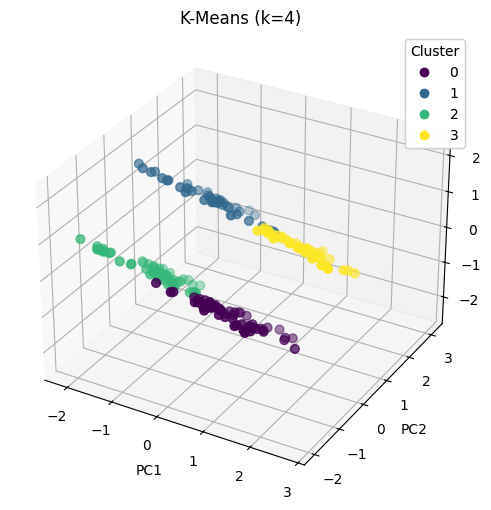

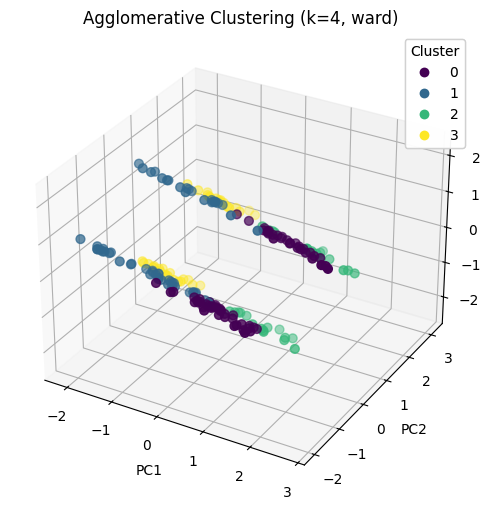

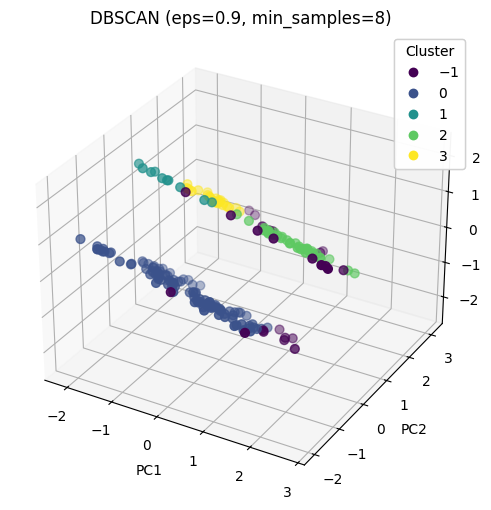

In [17]:
final_kmeans = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X_scaled)
plot_clusters_3d(X_pca, final_kmeans.labels_, "K-Means (k=4)")

labels_agg = AgglomerativeClustering(n_clusters=4, linkage="ward").fit_predict(X_scaled)
plot_clusters_3d(X_pca, labels_agg, "Agglomerative Clustering (k=4, ward)")

plot_clusters_3d(X_pca, labels_dbscan, "DBSCAN (eps=0.9, min_samples=8)")

## Tabla comparativa final

| Método | Parámetros | N° de clusters | N° de puntos de ruido | Silhouette Score |
|---|---|---:|---:|---:|
| K-Means | `k = 4` | 4 | N/A | 0.298 |
| Agglomerative | `k = 4, linkage="ward"` | 4 | N/A | 0.263 |
| DBSCAN | `eps = 0.9, min_samples = 8` | 4 | 25 | 0.269 |

# Clases naturales.

En la visualización 3d se evidencia una división primaria de los datos en 2 clústers muy separados, nuestra interpretación de esto es que se debe a la naturaleza binaria de la característica género, con un comportamiento análogo entre estos observado en las visualizaciones de KMEANS y del Aglomerativo. 

Dada la mayor silhouette score de KMEANS y su distribución con límites más discernibles respecto al aglomerativo, este sería el método de clústering utilizado para  generar las etiquetas.

# Análisis de los clusters de K-Means

Gender          Female  Male
Cluster_KMeans              
0                   56     0
1                    0    46
2                   56     0
3                    0    42

Gender          Female   Male
Cluster_KMeans               
0                100.0    0.0
1                  0.0  100.0
2                100.0    0.0
3                  0.0  100.0


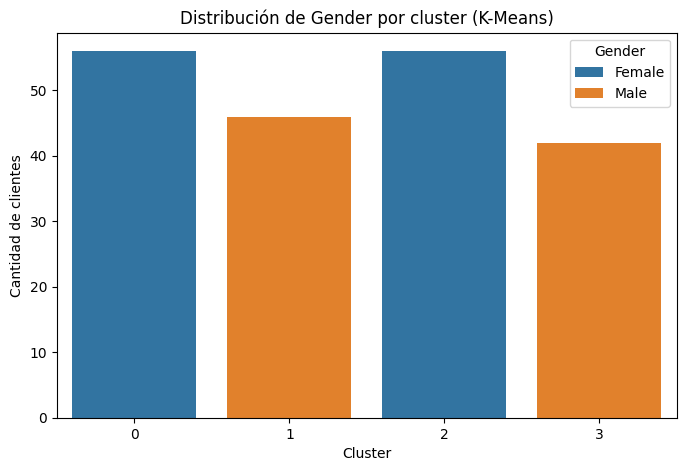

In [18]:
df['Cluster_KMeans'] = final_kmeans.labels_

gender_dist = pd.crosstab(df['Cluster_KMeans'], df['Gender'])
print(gender_dist)
print()
print((gender_dist.div(gender_dist.sum(axis=1), axis=0) * 100).round(1))

plt.figure(figsize=(8, 5))
sns.countplot(x='Cluster_KMeans', hue='Gender', data=df)
plt.title('Distribución de Gender por cluster (K-Means)')
plt.xlabel('Cluster')
plt.ylabel('Cantidad de clientes')
plt.show()

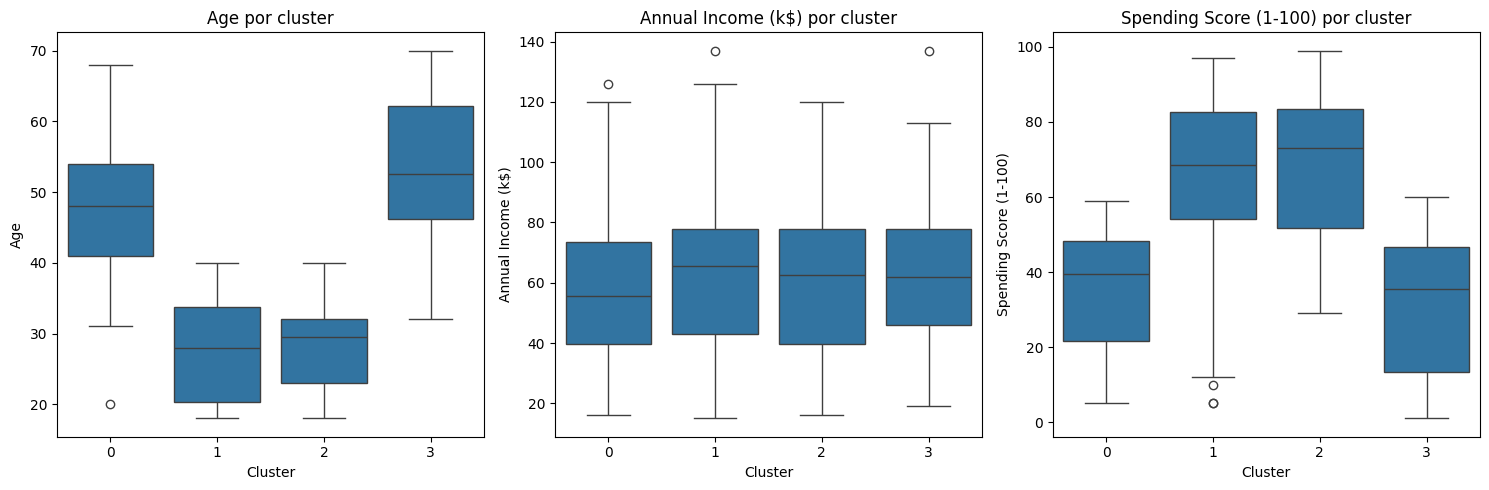

In [19]:
numeric_features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for feature, ax in zip(numeric_features, axes):
    sns.boxplot(x='Cluster_KMeans', y=feature, data=df, ax=ax)
    ax.set_title(f'{feature} por cluster')
    ax.set_xlabel('Cluster')

plt.tight_layout()
plt.show()

## Clústers:

Observamos que la agrupación vista en 2 grupos de 2 clústers corresponden a los clústers 0 y 2 (Mujeres) y 1 y 3 (Hombres). Las distribuciones de las variables muestran comportamiento análogo entre los géneros, específicamente, los clústers 1 y 2 tienen comportamiento similar tanto en edad como en Spending score, lo mismo puede decirse de los clústers 0 y 3.

Esta observación nos lleva a replantear los 4 clústers, pues a pesar de que vemos 2 regiones separadas claramente relacionadas al género, hay en ambas un patrón que muestra que los clientes tienen dos patrones de comportamiento transversales al género, lo que permitiría segmentarlos probablemente en dos grupos:

1. Personas entre los 18 y 40 años con spending scores entre 30 y 100
2. Personas entre los 30 y 70 años con spending scores entre 30 y 100

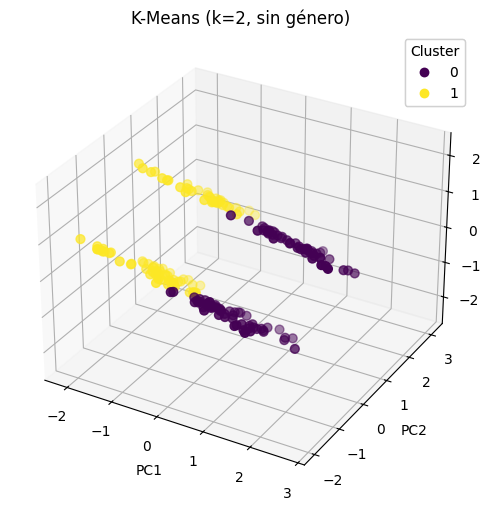

Silhouette: 0.33547192894004574


In [22]:
X_genderless = X_scaled[:, 1:]  # excluye Genre_encoded (columna 0): Age, Annual Income (k$), Spending Score (1-100)
genderless_kmeans = KMeans(n_clusters=2, random_state=42, n_init=10).fit(X_genderless)
plot_clusters_3d(X_pca, genderless_kmeans.labels_, "K-Means (k=2, sin género)")

print("Silhouette:", silhouette_score(X_genderless, genderless_kmeans.labels_))

## Análisis de los clusters K-Means (k=2, sin género)

Gender             Female  Male
Cluster_KMeans_k2              
0                      55    48
1                      57    40

Gender             Female  Male
Cluster_KMeans_k2              
0                    53.4  46.6
1                    58.8  41.2


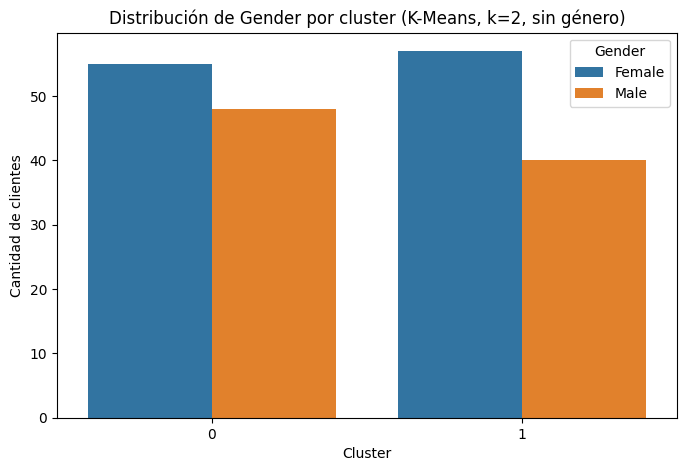

In [23]:
df['Cluster_KMeans_k2'] = genderless_kmeans.labels_

gender_dist_k2 = pd.crosstab(df['Cluster_KMeans_k2'], df['Gender'])
print(gender_dist_k2)
print()
print((gender_dist_k2.div(gender_dist_k2.sum(axis=1), axis=0) * 100).round(1))

plt.figure(figsize=(8, 5))
sns.countplot(x='Cluster_KMeans_k2', hue='Gender', data=df)
plt.title('Distribución de Gender por cluster (K-Means, k=2, sin género)')
plt.xlabel('Cluster')
plt.ylabel('Cantidad de clientes')
plt.show()

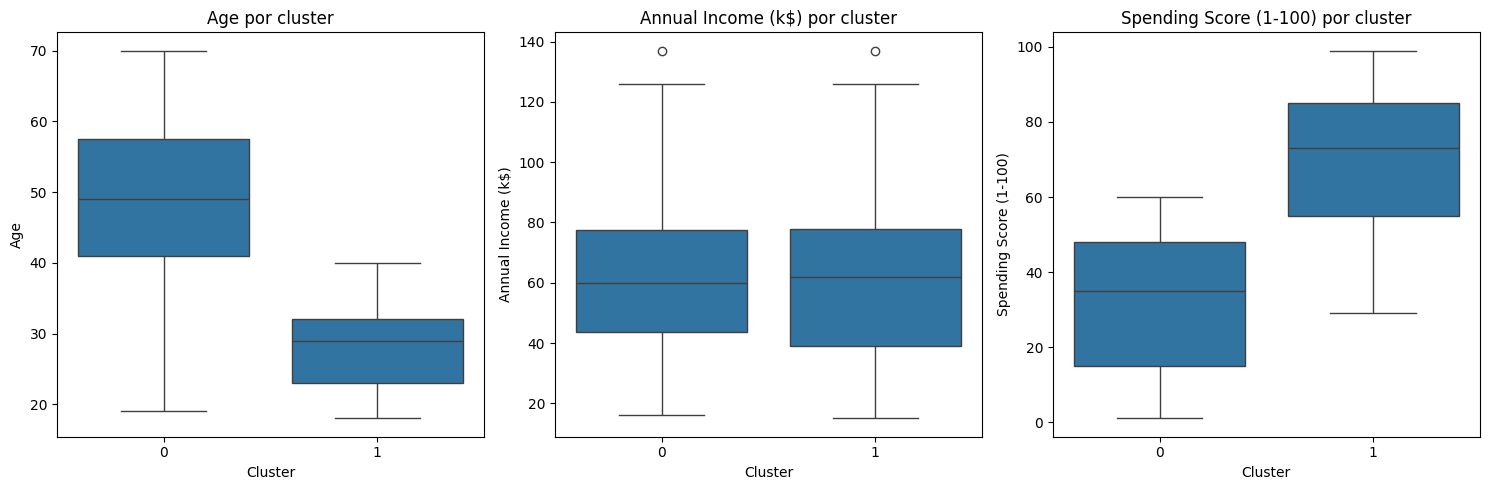

In [24]:
numeric_features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for feature, ax in zip(numeric_features, axes):
    sns.boxplot(x='Cluster_KMeans_k2', y=feature, data=df, ax=ax)
    ax.set_title(f'{feature} por cluster')
    ax.set_xlabel('Cluster')

plt.tight_layout()
plt.show()